In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from russian_rates.analysis import align_ruonia_with_key_rate
from russian_rates.models import (
    prepare_transitions,
    calibrate_profile,
    conditional_moments,
    standardized_residuals
)

In [2]:
ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file()
)

data_dir = ROOT / "data" / "processed"

ruonia = pd.read_parquet(data_dir / "ruonia.parquet")
key_rate = pd.read_parquet(data_dir / "key_rate.parquet")

df = align_ruonia_with_key_rate(ruonia, key_rate)
df = df.dropna(subset=["spread_pp"])
df = df.sort_values("date").reset_index(drop=True)

train = df[df["date"] >= "2023-01-01"]

r0, r1, dt = prepare_transitions(
    train, "spread_pp"
)

fit = calibrate_profile(
    r0, r1, dt,
    a_bounds=(0.001, 200.0)
)

a = fit["a"]
b = fit["b"]
sigma = fit["sigma"]

# Последние наблюдаемые значения
s0 = df["spread_pp"].iloc[-1] / 100
key0 = df["key_rate_pct"].iloc[-1]
start_date = df["date"].iloc[-1]

print(f"a = {a:.4f}")
print(f"b = {b * 100:.4f} п.п.")
print(f"sigma = {sigma * 100:.4f} п.п./√год")
print(f"Начальный спред = {s0 * 100:.4f} п.п.")
print(f"Последняя ключевая ставка = {key0:.2f}%")
print(f"Дата начала: {start_date.date()}")

a = 42.8224
b = -0.2113 п.п.
sigma = 2.9518 п.п./√год
Начальный спред = 0.0700 п.п.
Последняя ключевая ставка = 14.00%
Дата начала: 2026-11-20


In [3]:
n_paths = 10_000
horizon_days = 90

rng = np.random.default_rng(42)

dates = pd.date_range(
    start=start_date,
    periods=horizon_days + 1,
    freq="D",
)

paths = np.empty((horizon_days + 1, n_paths))

# Все траектории начинаются с одного спреда
paths[0, :] = s0

for t in range(1, len(dates)):

    delta_t = (dates[t] - dates[t - 1]).days / 365

    mu, var = conditional_moments(
        a, b, sigma,
        paths[t - 1, :],
        delta_t,
    )

    shocks = rng.standard_normal(n_paths)

    paths[t, :] = mu + np.sqrt(var) * shocks

print("Размер массива:", paths.shape)

Размер массива: (91, 10000)


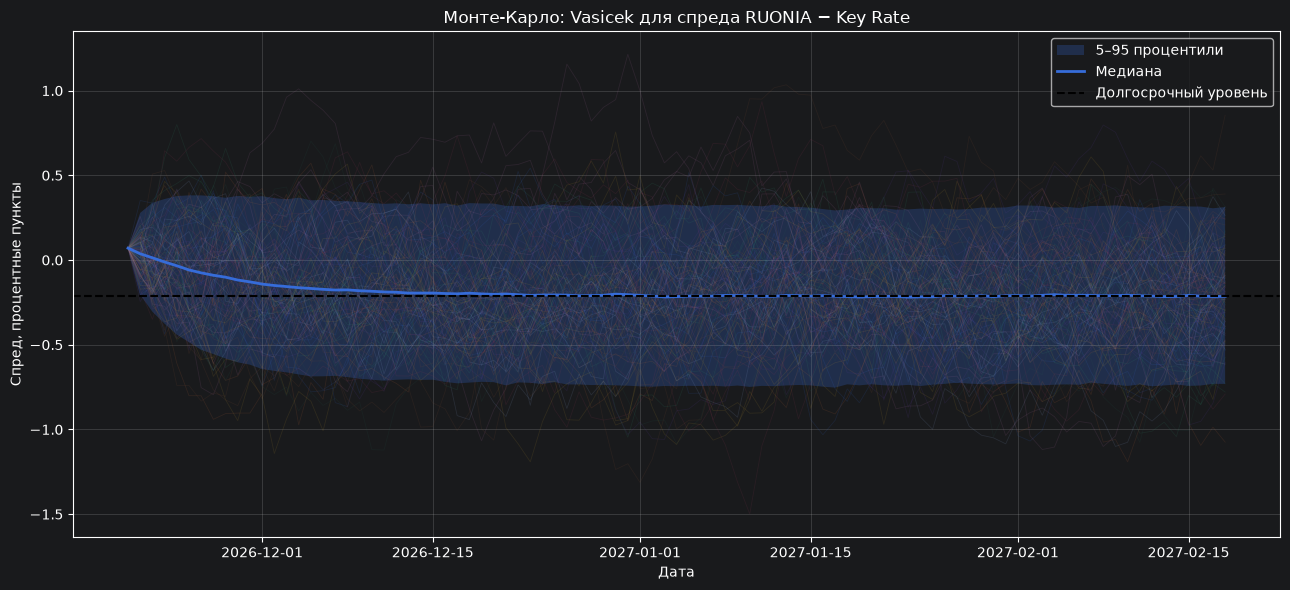

In [5]:
# Переводим спред обратно в процентные пункты
spread_paths = paths * 100

q05, q50, q95 = np.quantile(
    spread_paths,
    [0.05, 0.50, 0.95],
    axis=1
)

plt.figure(figsize=(13, 6))

# Показываем 100 отдельных траекторий
plt.plot(
    dates,
    spread_paths[:, :100],
    alpha=0.12,
    linewidth=0.6
)

plt.fill_between(
    dates,
    q05,
    q95,
    alpha=0.25,
    label="5–95 процентили"
)

plt.plot(
    dates,
    q50,
    linewidth=2,
    label="Медиана"
)

plt.axhline(
    b * 100,
    linestyle="--",
    color="black",
    label="Долгосрочный уровень"
)

plt.title("Монте-Карло: Vasicek для спреда RUONIA − Key Rate")
plt.ylabel("Спред, процентные пункты")
plt.xlabel("Дата")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
T = horizon_days / 365

mu_T, var_T = conditional_moments(
    a, b, sigma,
    s0, T
)

print("Через 90 календарных дней:")
print()

print("Аналитическое ожидание:",
      round(float(mu_T) * 100, 4), "п.п.")

print("Среднее Монте-Карло:",
      round(spread_paths[-1].mean(), 4), "п.п.")

print()
print("Аналитическое Std:",
      round(float(np.sqrt(var_T)) * 100, 4), "п.п.")

print("Std Монте-Карло:",
      round(spread_paths[-1].std(ddof=1), 4), "п.п.")

Через 90 календарных дней:

Аналитическое ожидание: -0.2113 п.п.
Среднее Монте-Карло: -0.2112 п.п.

Аналитическое Std: 0.319 п.п.
Std Монте-Карло: 0.3189 п.п.


In [7]:
days = np.arange(horizon_days + 1)

key_scenarios = {
    "Без изменений": np.full(
        len(dates), key0
    ),

    "Повышение +2 п.п.": (
        key0 + 2 * (days >= 30)
    ),

    "Снижение −2 п.п.": (
        key0 - 2 * (days >= 30)
    ),
}

ruonia_scenarios = {}

for name, key_path in key_scenarios.items():
    # spread_paths уже выражены в п.п.
    ruonia_scenarios[name] = (
        key_path[:, None] + spread_paths
    )

# Итоговое распределение через 90 дней
results = []

for name, scenario_paths in ruonia_scenarios.items():
    final_rates = scenario_paths[-1]

    results.append({
        "Сценарий": name,
        "Средняя RUONIA, %": final_rates.mean(),
        "5-й процентиль": np.quantile(final_rates, 0.05),
        "Медиана": np.median(final_rates),
        "95-й процентиль": np.quantile(final_rates, 0.95),
    })

scenario_results = pd.DataFrame(results)

display(scenario_results.round(4))

,Сценарий,"Средняя RUONIA, %",5-й процентиль,Медиана,95-й процентиль
0,Без изменений,13.7888,13.2689,13.7856,14.3127
1,Повышение +2 п.п.,15.7888,15.2689,15.7856,16.3127
2,Снижение −2 п.п.,11.7888,11.2689,11.7856,12.3127


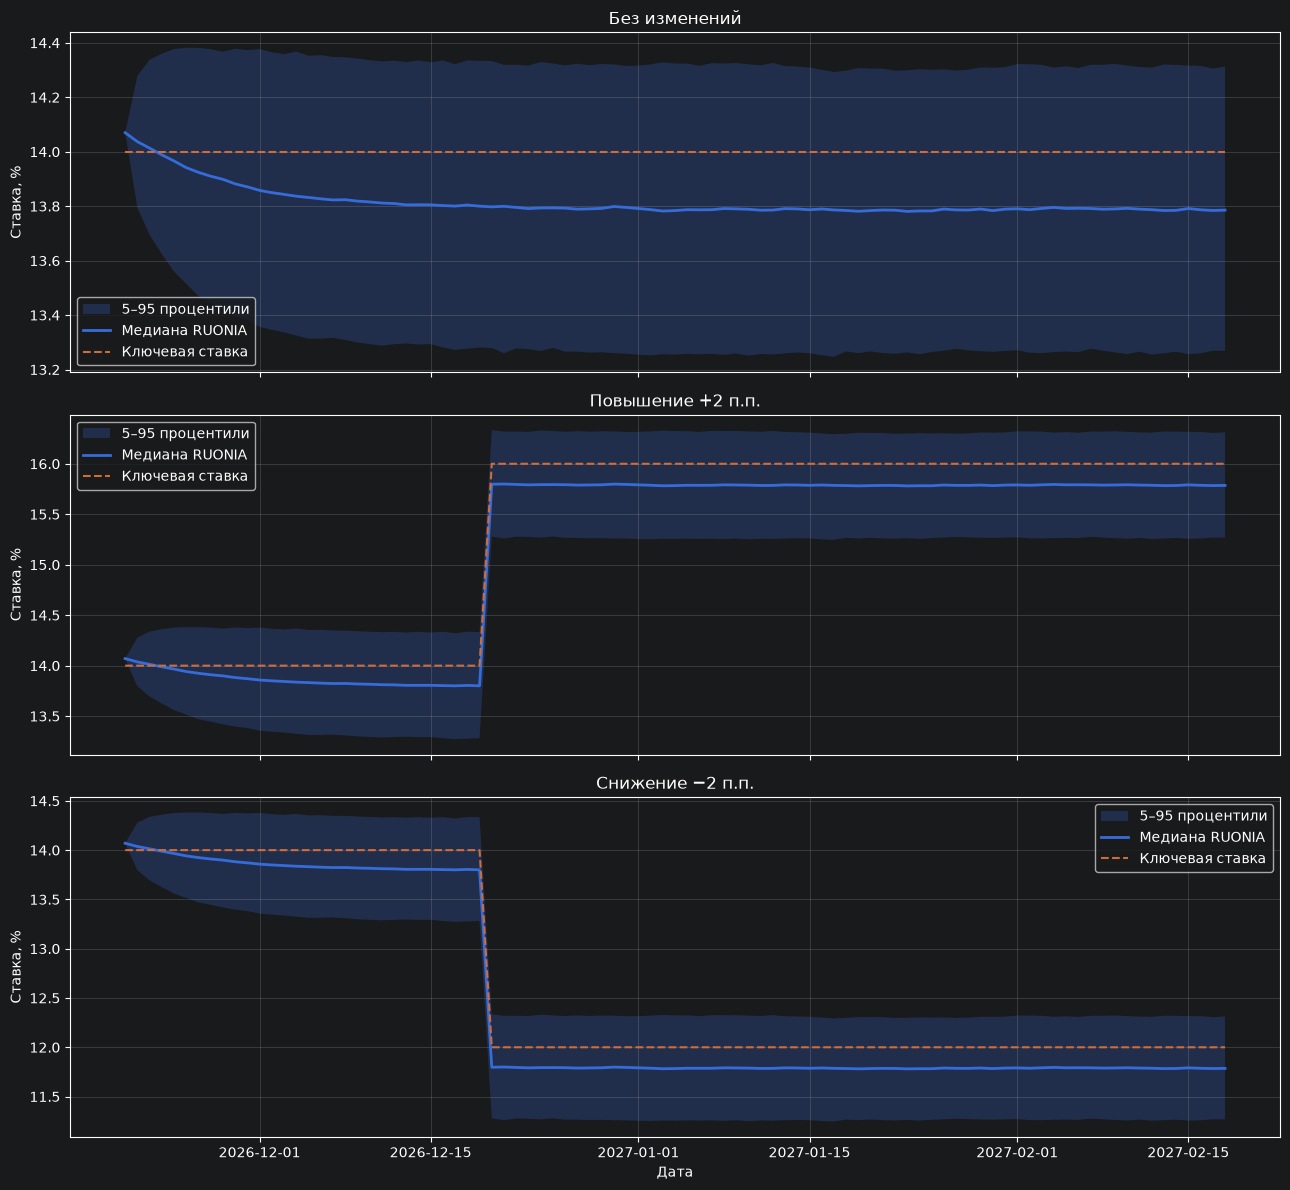

In [9]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(13, 12),
    sharex=True
)

for ax, (name, scenario_paths) in zip(
    axes, ruonia_scenarios.items()
):
    q05, q50, q95 = np.quantile(
        scenario_paths,
        [0.05, 0.50, 0.95],
        axis=1
    )

    ax.fill_between(
        dates, q05, q95,
        alpha=0.25,
        label="5–95 процентили"
    )

    ax.plot(
        dates, q50,
        linewidth=2,
        label="Медиана RUONIA"
    )

    ax.plot(
        dates, key_scenarios[name],
        linestyle="--",
        label="Ключевая ставка"
    )

    ax.set_title(name)
    ax.set_ylabel("Ставка, %")
    ax.grid(alpha=0.3)
    ax.legend()

plt.xlabel("Дата")
plt.tight_layout()
plt.show()

In [11]:
# Стандартизированные исторические инновации
z_hist = standardized_residuals(
    a, b, sigma,
    r0, r1, dt
)

# Приводим эмпирическое распределение
# к нулевому среднему и единичной дисперсии
z_hist = (
    z_hist - z_hist.mean()
) / z_hist.std(ddof=0)

print(f"Число исторических инноваций: {len(z_hist)}")
print(f"Среднее: {z_hist.mean():.6f}")
print(f"Std: {z_hist.std(ddof=0):.6f}")
print(f"Минимум: {z_hist.min():.4f}")
print(f"Максимум: {z_hist.max():.4f}")

Число исторических инноваций: 957
Среднее: 0.000000
Std: 1.000000
Минимум: -5.8176
Максимум: 5.1273


In [12]:
bootstrap_rng = np.random.default_rng(123)

bootstrap_paths = np.empty_like(paths)
bootstrap_paths[0, :] = s0

for t in range(1, len(dates)):
    delta_t = (
        dates[t] - dates[t - 1]
    ).days / 365

    mu, var = conditional_moments(
        a, b, sigma,
        bootstrap_paths[t - 1, :],
        delta_t,
    )

    # Случайно выбираем исторические инновации
    shocks = bootstrap_rng.choice(
        z_hist,
        size=n_paths,
        replace=True,
    )

    bootstrap_paths[t, :] = (
        mu + np.sqrt(var) * shocks
    )

bootstrap_spread_pp = bootstrap_paths * 100

print("Размер массива:", bootstrap_paths.shape)

Размер массива: (91, 10000)


In [14]:
simulations = {
    "Gaussian": spread_paths,
    "Historical Bootstrap": bootstrap_spread_pp,
}

comparison = []

for name, sim in simulations.items():

    terminal = sim[-1]

    # Изменения спреда за один календарный день
    changes = np.diff(sim, axis=0)

    # Отклонения спреда от долгосрочного уровня
    deviations = np.abs(sim - b * 100)

    comparison.append({
        "Модель": name,
        "Среднее T=90": terminal.mean(),
        "Std T=90": terminal.std(ddof=1),
        "1%": np.quantile(terminal, 0.01),
        "5%": np.quantile(terminal, 0.05),
        "95%": np.quantile(terminal, 0.95),
        "99%": np.quantile(terminal, 0.99),
        "P(|Δs| > 0.5 п.п.), %": (
            np.mean(
                np.max(np.abs(changes), axis=0) > 0.5
            ) * 100
        ),
        "P(|s-b| > 1 п.п.), %": (
            np.mean(
                np.max(deviations, axis=0) > 1.0
            ) * 100
        ),
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Модель,Среднее T=90,Std T=90,1%,5%,95%,99%,"P(|Δs| > 0.5 п.п.), %","P(|s-b| > 1 п.п.), %"
0,Gaussian,-0.2112,0.3189,-0.9501,-0.7311,0.3127,0.5329,7.61,7.22
1,Historical Bootstrap,-0.2122,0.3157,-0.9567,-0.7177,0.3188,0.6040,70.34,16.12


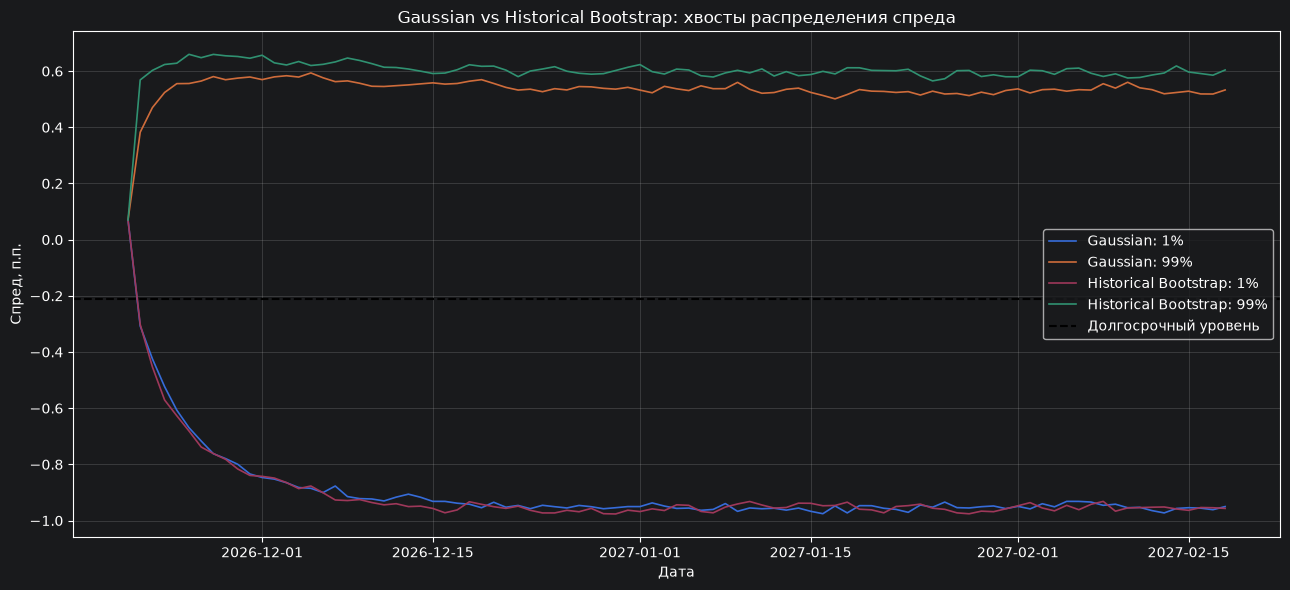

In [15]:
plt.figure(figsize=(13, 6))

for name, sim in simulations.items():

    q01, q99 = np.quantile(
        sim, [0.01, 0.99], axis=1
    )

    plt.plot(
        dates, q01,
        linewidth=1.2,
        label=f"{name}: 1%"
    )

    plt.plot(
        dates, q99,
        linewidth=1.2,
        label=f"{name}: 99%"
    )

plt.axhline(
    b * 100,
    linestyle="--",
    color="black",
    label="Долгосрочный уровень"
)

plt.title(
    "Gaussian vs Historical Bootstrap: "
    "хвосты распределения спреда"
)

plt.xlabel("Дата")
plt.ylabel("Спред, п.п.")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()